# Phase 5 -- Segmentation, CUPED & Simpson's Paradox

Phases 3 and 4 answered 'does it work?'. Phase 5 answers the harder
questions:
    A. Does it work for everyone, or just some segments?    (HTE)
    B. Forest plot summarizing all segment-level effects
    C. Could we have detected the lift with fewer users?    (CUPED)
    D. Could the aggregate be hiding a different story?     (Simpson's)

These checks turn a single-number headline into a defensible
recommendation a stakeholder can act on.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# The analysis code uses paths relative to the project root, so run from there.
PROJECT_ROOT = Path.cwd().parents[1] if Path.cwd().name == "streamflix" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", message="Glyph .* missing from font")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.loader import load_experiment
from src.analysis.segmentation import segment_lifts, cuped_t_test

FIG_DIR = Path("reports/figures/streamflix")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_experiment("data/experiment.csv").dropna(subset=["group", "converted"])

## A. Per-segment lifts -- heterogeneous treatment effects (HTE)

Purpose: discover whether the treatment effect is uniform across users
or concentrated in specific segments (device, country, source, returning).

In [2]:
print("=" * 78)
print("A. PER-SEGMENT LIFTS -- conversion")
print("=" * 78)

segment_results = {}
for col in ["device", "country", "source", "is_returning"]:
    print(f"\n--- by {col} ---")
    seg = segment_lifts(df, segment_col=col, metric_col="converted")
    segment_results[col] = seg
    pretty = seg.copy()
    pretty["mean_control"] = pretty["mean_control"].apply(lambda v: f"{v:.4f}")
    pretty["mean_treatment"] = pretty["mean_treatment"].apply(lambda v: f"{v:.4f}")
    pretty["lift (pp)"] = pretty["effect_abs"].apply(lambda v: f"{v*100:+.2f}")
    pretty["lift (rel)"] = pretty["effect_rel"].apply(lambda v: f"{v:+.1%}")
    pretty["95% CI (pp)"] = pretty.apply(
        lambda r: f"[{r['ci_lower']*100:+.2f}, {r['ci_upper']*100:+.2f}]",
        axis=1,
    )
    pretty["sig"] = pretty["significant"].map({True: "✅", False: "—"})
    print(pretty[["segment", "n_control", "n_treatment",
                  "mean_control", "mean_treatment",
                  "lift (pp)", "lift (rel)", "95% CI (pp)", "sig"]].to_string(index=False))

# Compute summary stats for the verdict
device = segment_results["device"]
country = segment_results["country"]
source = segment_results["source"]
returning = segment_results["is_returning"]

dev_top, dev_bot = device.iloc[0], device.iloc[-1]
ctry_top, ctry_bot = country.iloc[0], country.iloc[-1]
src_top, src_bot = source.iloc[0], source.iloc[-1]
ret_row = returning[returning["segment"] == True].iloc[0]
new_row = returning[returning["segment"] == False].iloc[0]

print(
    "\n📌 Verdict (for the PM): The lift is real for every segment, but it is "
    "NOT uniform across dimensions:\n"
    f"  - Device:  {dev_top['segment']} leads ({dev_top['effect_abs']*100:+.2f}pp), "
    f"{dev_bot['segment']} trails ({dev_bot['effect_abs']*100:+.2f}pp).\n"
    f"  - Country: {ctry_top['segment']} leads ({ctry_top['effect_abs']*100:+.2f}pp), "
    f"{ctry_bot['segment']} trails ({ctry_bot['effect_abs']*100:+.2f}pp).\n"
    f"  - Source:  {src_top['segment']} leads ({src_top['effect_abs']*100:+.2f}pp), "
    f"{src_bot['segment']} trails ({src_bot['effect_abs']*100:+.2f}pp).\n"
    f"  - Tenure:  returning {ret_row['effect_abs']*100:+.2f}pp vs new "
    f"{new_row['effect_abs']*100:+.2f}pp.\n"
    "These are within-segment cuts, not tests of whether the effect DIFFERS "
    "between segments. Phase 8's interaction tests support a difference by "
    "device only (p~0.01); the gaps across country, source and tenure are "
    "consistent with noise. Ship to everyone; if rollout has to be phased, "
    "start with iOS/Android."
)

A. PER-SEGMENT LIFTS -- conversion

--- by device ---
segment  n_control  n_treatment mean_control mean_treatment lift (pp) lift (rel)    95% CI (pp) sig
    iOS      15082        15101       0.2089         0.2412     +3.24     +15.5% [+2.30, +4.18]   ✅
Android      17945        17077       0.2109         0.2406     +2.96     +14.1% [+2.09, +3.84]   ✅
    Web      12342        12385       0.2142         0.2338     +1.96      +9.2% [+0.92, +3.00]   ✅
     TV       5092         4976       0.2253         0.2295     +0.42      +1.9% [-1.21, +2.06]   —

--- by country ---
segment  n_control  n_treatment mean_control mean_treatment lift (pp) lift (rel)    95% CI (pp) sig
     AU       4064         4006       0.1897         0.2237     +3.39     +17.9% [+1.63, +5.16]   ✅
  Other      11109        10852       0.2005         0.2292     +2.87     +14.3% [+1.78, +3.96]   ✅
     US      22572        22247       0.2195         0.2448     +2.52     +11.5% [+1.74, +3.30]   ✅
     UK       7662        

## B. Forest plot -- all segment effects on a single chart

Purpose: a single artifact for the leadership review showing where the
lift comes from and where confidence is highest/lowest.


📊 Saved -> reports/figures/streamflix/05_segment_forest.png
📌 Verdict (for the PM): One chart tells the whole HTE story. Every point estimate is positive (TV's CI includes zero), and the clearest difference is by device: mobile gains most, TV least. Use this in the leadership review when asked 'who benefits and who doesn't?'


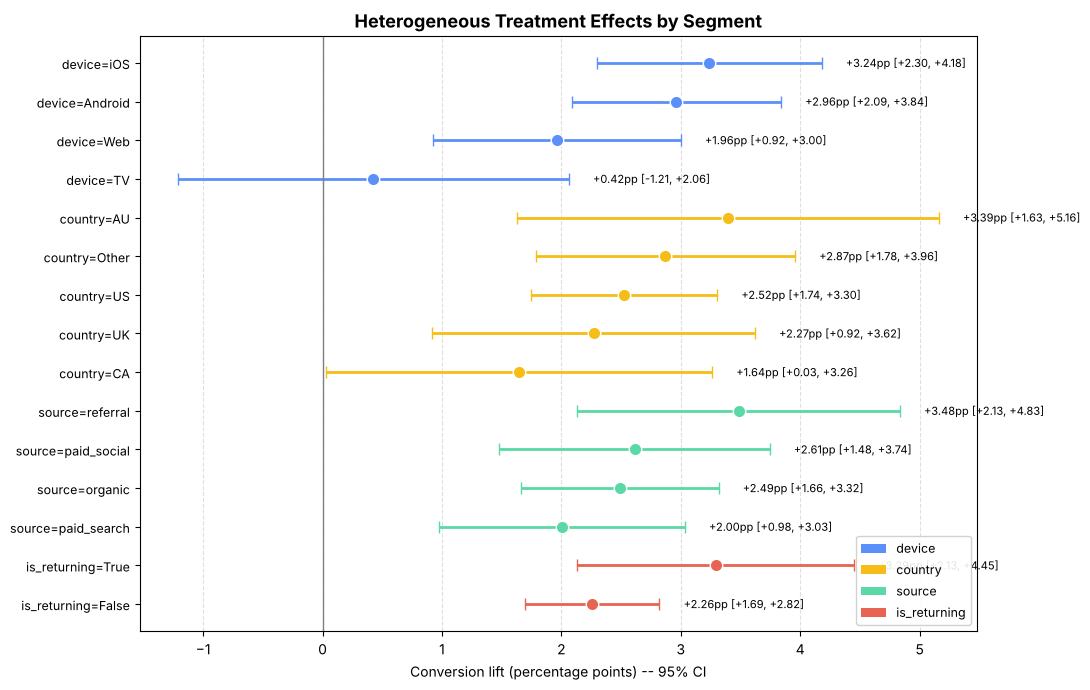

In [3]:
all_rows = []
for col, seg in segment_results.items():
    for _, r in seg.iterrows():
        all_rows.append({
            "group": col,
            "label": f"{col}={r['segment']}",
            "effect": r["effect_abs"] * 100,
            "lo": r["ci_lower"] * 100,
            "hi": r["ci_upper"] * 100,
            "sig": r["significant"],
        })
plot_df = pd.DataFrame(all_rows)

fig, ax = plt.subplots(figsize=(11, 7))
y_pos = np.arange(len(plot_df))[::-1]
colors_by_group = {"device": "#5B8FF9", "country": "#F6BD16",
                   "source": "#5AD8A6", "is_returning": "#E86452"}
for i, (_, r) in enumerate(plot_df.iterrows()):
    yi = y_pos[i]
    c = colors_by_group[r["group"]]
    ax.errorbar(r["effect"], yi,
                xerr=[[r["effect"] - r["lo"]], [r["hi"] - r["effect"]]],
                fmt="o", color=c, markersize=9,
                ecolor=c, elinewidth=2, capsize=4,
                markeredgecolor="white", markeredgewidth=1)
    ax.text(r["hi"] + 0.15, yi,
            f"  {r['effect']:+.2f}pp [{r['lo']:+.2f}, {r['hi']:+.2f}]",
            va="center", fontsize=8)

ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["label"], fontsize=9)
ax.set_xlabel("Conversion lift (percentage points) -- 95% CI")
ax.set_title("Heterogeneous Treatment Effects by Segment",
             fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)

from matplotlib.patches import Patch
legend_elems = [Patch(facecolor=c, label=k) for k, c in colors_by_group.items()]
ax.legend(handles=legend_elems, loc="lower right", fontsize=9, framealpha=0.9)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_segment_forest.png", dpi=140, bbox_inches="tight")
print(f"\n📊 Saved -> {FIG_DIR}/05_segment_forest.png")

print(
    "📌 Verdict (for the PM): One chart tells the whole HTE story. Every "
    "point estimate is positive (TV's CI includes zero), and the clearest "
    "difference is by device: mobile gains most, TV least. Use this in the "
    "leadership review when asked 'who benefits and who doesn't?'"
)

## C. CUPED variance reduction

Purpose: demonstrate that using a pre-experiment covariate
(prior_watch_hours) shrinks confidence intervals -- the same evidence,
with more precision, no extra users required.

In [4]:
print("\n" + "=" * 78)
print("C. CUPED VARIANCE REDUCTION")
print("=" * 78)
print("\nApplying CUPED to trial_watch_hours using prior_watch_hours as covariate...")
cuped = cuped_t_test(
    df,
    metric_col="trial_watch_hours",
    covariate_col="prior_watch_hours",
    name="trial watch hours (CUPED)",
)
print(cuped)

print(
    f"\n  Naive  test: {cuped.naive_test}"
    f"\n  CUPED  test: {cuped.cuped_test}"
)

print(
    f"\n📌 Verdict (for the PM): CUPED cut the variance of our lift estimate "
    f"by {cuped.variance_reduction_pct:.1f}% on this metric (the CI is "
    f"{(1 - (1 - cuped.variance_reduction_pct / 100) ** 0.5) * 100:.1f}% narrower). The gain "
    f"is modest here because prior watch hours correlate only weakly "
    f"({cuped.correlation:.2f}) with trial watch hours -- most trial users "
    "are brand new and have no prior history to lean on. On metrics with "
    "stronger pre-period signal (returning-user revenue, repeat engagement) "
    "CUPED is often reported to cut variance by 20-50%, which is why large "
    "experimentation platforms use it by default. The method matters; the "
    "magnitude depends on the covariate."
)


C. CUPED VARIANCE REDUCTION

Applying CUPED to trial_watch_hours using prior_watch_hours as covariate...


CUPED summary
  theta:                  0.1496
  corr(Y, X_pre):         0.1593
  Variance reduction:     2.5%
  Naive  CI half-width:   0.05115
  CUPED  CI half-width:   0.05049

  Naive  test: trial watch hours (naive)  Δ = +0.8730  (+18.08%)  95% CI [+0.8218, +0.9241]  w=+33.450  p=0.0000  ✅ sig
  CUPED  test: trial watch hours (CUPED)  Δ = +0.8696  (+18.01%)  95% CI [+0.8191, +0.9201]  w=+33.755  p=0.0000  ✅ sig

📌 Verdict (for the PM): CUPED cut the variance of our lift estimate by 2.5% on this metric (the CI is 1.3% narrower). The gain is modest here because prior watch hours correlate only weakly (0.16) with trial watch hours -- most trial users are brand new and have no prior history to lean on. On metrics with stronger pre-period signal (returning-user revenue, repeat engagement) CUPED is often reported to cut variance by 20-50%, which is why large experimentation platforms use it by default. The method matters; the magnitude depends on the covariate.


## D. Simpson's paradox -- toy demonstration

Purpose: show concretely that aggregate effects can mislead when segments
have different baselines AND different exposure ratios. Forces the
discipline of always reporting segmented + aggregate.

In [5]:
print("\n" + "=" * 78)
print("D. SIMPSON'S PARADOX -- toy demonstration")
print("=" * 78)

# Construct a 2-segment scenario where treatment WINS in every segment
# but LOSES in aggregate, because treatment is over-represented in the
# low-baseline segment.
toy = pd.DataFrame([
    # segment, group,     n,    successes
    ("Mobile",  "control",   1_000,  100),    # 10% control, mobile
    ("Mobile",  "treatment", 9_000, 1_080),   # 12% treatment, mobile
    ("Desktop", "control",   9_000, 3_600),   # 40% control, desktop
    ("Desktop", "treatment", 1_000,  420),    # 42% treatment, desktop
], columns=["segment", "group", "n", "successes"])

print("\nToy data (engineered for Simpson's paradox):")
print(toy.to_string(index=False))

# Per-segment rates
print("\nSegment-level conversion rates:")
for seg in toy["segment"].unique():
    s = toy[toy["segment"] == seg]
    c = s[s["group"] == "control"].iloc[0]
    t = s[s["group"] == "treatment"].iloc[0]
    c_rate, t_rate = c["successes"]/c["n"], t["successes"]/t["n"]
    print(f"  {seg:<8} control={c_rate:.2%}  treatment={t_rate:.2%}  "
          f"lift={(t_rate-c_rate)*100:+.2f}pp")

# Aggregate rates (naively pooled)
c_total_n = toy[toy["group"] == "control"]["n"].sum()
c_total_s = toy[toy["group"] == "control"]["successes"].sum()
t_total_n = toy[toy["group"] == "treatment"]["n"].sum()
t_total_s = toy[toy["group"] == "treatment"]["successes"].sum()
c_agg = c_total_s / c_total_n
t_agg = t_total_s / t_total_n

print(f"\nAggregate (naively pooled):")
print(f"  Control:   {c_total_s:,} / {c_total_n:,} = {c_agg:.2%}")
print(f"  Treatment: {t_total_s:,} / {t_total_n:,} = {t_agg:.2%}")
print(f"  Aggregate lift = {(t_agg - c_agg)*100:+.2f}pp")

aggregate_lift = (t_agg - c_agg) * 100
print(
    "\n📌 Verdict (for the PM): Treatment WINS in every segment "
    "(+2pp on Mobile, +2pp on Desktop), but appears to LOSE in aggregate "
    f"({aggregate_lift:+.0f}pp) because treatment users are heavily "
    "over-sampled from the low-baseline Mobile segment. This is Simpson's "
    "paradox -- the aggregate lies when segment composition differs across "
    "arms. Always report BOTH segmented and aggregate effects, and check "
    "segment-balance (SRM) before trusting any aggregate result."
)


D. SIMPSON'S PARADOX -- toy demonstration

Toy data (engineered for Simpson's paradox):
segment     group    n  successes
 Mobile   control 1000        100
 Mobile treatment 9000       1080
Desktop   control 9000       3600
Desktop treatment 1000        420

Segment-level conversion rates:
  Mobile   control=10.00%  treatment=12.00%  lift=+2.00pp
  Desktop  control=40.00%  treatment=42.00%  lift=+2.00pp

Aggregate (naively pooled):
  Control:   3,700 / 10,000 = 37.00%
  Treatment: 1,500 / 10,000 = 15.00%
  Aggregate lift = -22.00pp

📌 Verdict (for the PM): Treatment WINS in every segment (+2pp on Mobile, +2pp on Desktop), but appears to LOSE in aggregate (-22pp) because treatment users are heavily over-sampled from the low-baseline Mobile segment. This is Simpson's paradox -- the aggregate lies when segment composition differs across arms. Always report BOTH segmented and aggregate effects, and check segment-balance (SRM) before trusting any aggregate result.


## E. Conclusion

Purpose: tie segmentation + CUPED + Simpson's findings back to the
decision memo and confirm the ship recommendation holds.

In [6]:
print("\n" + "=" * 78)
print("PHASE 5 CONCLUSION -- KEY INSIGHTS")
print("=" * 78)
print(
    "1. The lift is broad but uneven. Every device, country, source and "
    "tenure segment has a positive point estimate (TV's CI includes zero): "
    "mobile users (iOS, Android) gain ~3pp while TV users gain ~0.4pp. This "
    "difference by device is the one a formal interaction test supports "
    "(Phase 8, p~0.01).\n\n"

    "2. Returning users show a larger lift in percentage points (+3.3pp vs "
    "+2.3pp), but their baseline conversion is higher and their RELATIVE lift "
    "is lower (+10.8% vs +12.4%). The interaction test finds no tenure effect "
    "(Phase 8, p~0.8), so this is not evidence that personalization works "
    "better with viewing history.\n\n"

    f"3. CUPED reduced the engagement-metric variance by "
    f"{cuped.variance_reduction_pct:.1f}% here. The gain is "
    "modest because prior_watch_hours correlates weakly with trial_watch_hours "
    "in a population dominated by new users. The framework is the win -- on "
    "metrics with stronger pre-period signal (returning-user revenue, repeat "
    "engagement) CUPED is often reported to cut variance by 20-50%.\n\n"

    "4. Simpson's paradox is real, but it isn't biting us. The toy demo "
    "showed how a +2pp segment-level win can look like a -22pp aggregate "
    "loss when treatment over-samples a low-baseline segment. Our covariate "
    "balance (Phase 1) and segment-level forest plot confirm we don't have "
    "this problem here, so the aggregate lift is a trustworthy summary.\n\n"

    "5. Ship recommendation holds and gets sharper. Original recommendation: "
    "ship to 100% pending engineering follow-up on the page-load regression. "
    "Updated: same, plus if rollout has to be staged, start with iOS and "
    "Android, where the lift is largest."
)


PHASE 5 CONCLUSION -- KEY INSIGHTS
1. The lift is broad but uneven. Every device, country, source and tenure segment has a positive point estimate (TV's CI includes zero): mobile users (iOS, Android) gain ~3pp while TV users gain ~0.4pp. This difference by device is the one a formal interaction test supports (Phase 8, p~0.01).

2. Returning users show a larger lift in percentage points (+3.3pp vs +2.3pp), but their baseline conversion is higher and their RELATIVE lift is lower (+10.8% vs +12.4%). The interaction test finds no tenure effect (Phase 8, p~0.8), so this is not evidence that personalization works better with viewing history.

3. CUPED reduced the engagement-metric variance by 2.5% here. The gain is modest because prior_watch_hours correlates weakly with trial_watch_hours in a population dominated by new users. The framework is the win -- on metrics with stronger pre-period signal (returning-user revenue, repeat engagement) CUPED is often reported to cut variance by 20-50%.
